In [105]:
import pandas as pd
import numpy as np
import tensorflow as tf

from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import StandardScaler,LabelEncoder
from keras.models import Sequential
from keras.layers import Dense,Dropout
print('Imported Successfully')

Imported Successfully


In [106]:
df = pd.read_csv('Datasets\\pokemon_data.csv')
df.head()

,Unnamed: 0,against_water,attack,capture_rate,classfication,defense,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,0,0.5,49,45,Seed Pokémon,49,65,65,45,grass,poison,6.9,1,0
1,1,0.5,62,45,Seed Pokémon,63,80,80,60,grass,poison,13.0,1,0
2,2,0.5,100,45,Seed Pokémon,123,122,120,80,grass,poison,100.0,1,0
3,5,2.0,104,45,Flame Pokémon,78,159,115,100,fire,flying,90.5,1,0
4,11,1.0,45,45,Butterfly Pokémon,50,90,80,70,bug,flying,32.0,1,0


In [107]:
df.drop(['Unnamed: 0'],axis=1)
df.drop(['classfication'],axis=1)
df.drop(['capture_rate'],axis=1)

df.head()

,Unnamed: 0,against_water,attack,capture_rate,classfication,defense,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,0,0.5,49,45,Seed Pokémon,49,65,65,45,grass,poison,6.9,1,0
1,1,0.5,62,45,Seed Pokémon,63,80,80,60,grass,poison,13.0,1,0
2,2,0.5,100,45,Seed Pokémon,123,122,120,80,grass,poison,100.0,1,0
3,5,2.0,104,45,Flame Pokémon,78,159,115,100,fire,flying,90.5,1,0
4,11,1.0,45,45,Butterfly Pokémon,50,90,80,70,bug,flying,32.0,1,0


In [108]:
for col in ['type1','type2']:
    df[col] = df[col].fillna('unknown')
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

In [109]:
x=  df.drop(columns=['is_legendary','classfication'])
y= df['is_legendary']

In [110]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [111]:
x_train,x_test,y_train,y_test = tts(
    x_scaled,y,test_size=.2,random_state=42,stratify=y
)

In [112]:
model = Sequential([
    Dense(64,input_dim=x_train.shape[1],activation='relu'),
    Dropout(.3),
    Dense(32,activation='relu'),
    Dropout(.2),
    Dense(1,activation='relu')
])

c:\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [113]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [114]:
history = model.fit(x_train,y_train,epochs=30,batch_size=16,validation_split=.2,verbose=1)

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8780 - loss: 1.7578 - val_accuracy: 0.9062 - val_loss: 1.5116
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8858 - loss: 1.7903 - val_accuracy: 0.9062 - val_loss: 1.5111
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8858 - loss: 1.7439 - val_accuracy: 0.9062 - val_loss: 1.5121
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8819 - loss: 1.7313 - val_accuracy: 0.9062 - val_loss: 1.3344
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8858 - loss: 1.7877 - val_accuracy: 0.9062 - val_loss: 1.3127
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8858 - loss: 1.6137 - val_accuracy: 0.9062 - val_loss: 1.3018
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8858 - loss: 1.7885 - val_accuracy: 0.9062 - val_loss: 1.3023
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8858 - loss: 1.6972 - val_accuracy: 0.8906 - val_loss

In [115]:
test_loss,test_acc = model.evaluate(x_test,y_test,verbose=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9000 - loss: 0.1377  


In [116]:
test_acc

0.8999999761581421

In [117]:
test_loss

0.1376975029706955

In [118]:
str(int(round(test_acc,2)*100)) + '%'

'90%'

In [119]:
str(int(round(test_loss,2)*100)) + '%'

'14%'

In [123]:
y_pred = model.predict(x_test)
y_pred

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


array([[0.        ],
       [0.        ],
       [0.        ],
       [0.41178957],
       [0.73265624],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.29599395],
       [0.304209  ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.0135723 ],
       [0.2687549 ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.03477205],
       [0.        ],
       [0.        ],
       [1.5498184 ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [1.5771574 ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.55375016],
       [0.        ],
       [0.4986464 ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.49768448],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.   

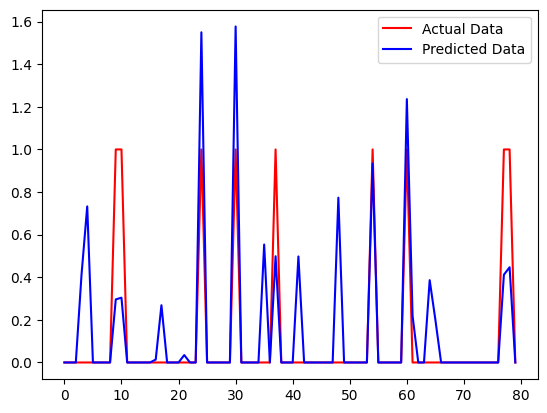

In [126]:
plt.plot(y_test.values,label='Actual Data',color='red')
plt.plot(y_pred,label='Predicted Data',color='blue')
plt.legend()
plt.show()